<a href="https://colab.research.google.com/github/JFish72/CSC-349-Machine-Learning-/blob/main/HW4/heart_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Task One:**


*   Simply taking the downloaded CSV files and placing them into a Pandas DataFrame. Must always be sure that the CSV has been uploaded properly into the folder section of Google Colab. For this assignment we are using the UCI heart disease dataset which I downloaded directly from Kaggle.

*   In this step, I also like to import most of the tools I know/think I will need for future tasks. This is a habit I've gained from coding in other languages and IDE's.









In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('heart_disease_uci.csv')

**Task Two:**


*   To complete a structural inspection of the DataFrame created, I will use the head(), info(), and describe() methods, which should give me enough information to go foward with creating my ML pipeline and eventually training my model. It is extremely important to understand the data you are working with before altering it or making assumptions. A key factor of this process is to identify which categories are numerical and which are categorical.
*   The info() method is the best at viewing the number of non-null values in our columns which is very helpful for the next steps of scrubbing the dataset. When using the describe() method, it is much cleaner to display the categories separately by setting the parameters.


In [9]:
display(df.head())

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


In [11]:
display(df.describe(include=[np.number]))

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


In [12]:
display(df.describe(include=["object", "category"]))

,sex,dataset,cp,fbs,restecg,exang,slope,thal
count,920,920,920,830,918,865,611,434
unique,2,4,4,2,3,2,3,3
top,Male,Cleveland,asymptomatic,False,normal,False,flat,normal
freq,726,304,496,692,551,528,345,196


**Task Three:**


*   From our machine learning class, one of the most important steps in the machine learning process and specifically understanding the data you are presented with, is the need to examine and scrub/replace missing or inaccurate data from a dataset. Without doing so, all other steps are void, and your model is pointless.
*   Once missing values have been discovered it is as simple as replacing numerical values with the median of that column and for categorical replacing them with the mode.



In [13]:
from sklearn.impute import SimpleImputer

display(df.isnull().sum())

df = df.replace('?', np.nan)
df = df.replace('N/A', np.nan)
df = df.replace('None', np.nan)
df = df.replace('Unavailable', np.nan)

display(df.isnull().sum()) # Results show the dataset does not contain any of the chosen strings as values.

numerical_imputer = SimpleImputer(strategy='median')

categorical_imputer = SimpleImputer(strategy='most_frequent')

,0
id,0
age,0
sex,0
dataset,0
cp,0
trestbps,59
chol,30
fbs,90
restecg,2
thalch,55


,0
id,0
age,0
sex,0
dataset,0
cp,0
trestbps,59
chol,30
fbs,90
restecg,2
thalch,55


**Task Four:**


*   Know that we have accounted for non-standard missing values and replaced them with the recognized null value, the null values must be replaced accordingly, as stated above. For this step though we have to treat the columns (numerical and categorical) separately, scale them and then bring them together, which is where our pipeline and columns transformers come into play.
*   During this step it is important to drop unnessary information for our Model such as the patient ID. If the information won't add value to our model, there is no point in wasting resources on it.
*   Since we will be recreating the preprocessing step for the SVC and DCT portions of this assignment, it will save me time to create a function for the whole preprocessing process. I find this to be much easier than past assignments, when I would rewrite the same lines of code from previous tasks.

In [14]:
from pandas.core.arrays import numeric
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X = df.drop(columns = ['num', 'id'])
y = (df['num'] > 0).astype(int)

numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()

categorical_features = X.select_dtypes(exclude=[np.number]).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

def create_preprocessor():
  numeric_pipeline = Pipeline([
      ('imputer', SimpleImputer(strategy='median')),
      ('scaler', StandardScaler())
  ])

  categorical_pipeline = Pipeline([
      ('imputer', SimpleImputer(strategy='most_frequent')),
      ('encoder', OneHotEncoder(handle_unknown='ignore'))
  ])

  preprocessor = ColumnTransformer([
      ('numeric', numeric_pipeline, numeric_features),
      ('categorical', categorical_pipeline, categorical_features)
  ])

  return preprocessor

preprocessing_pipeline = Pipeline([
    ('preprocessor', create_preprocessor())
])

display(preprocessing_pipeline)



Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalch', 'oldpeak', 'ca']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['sex', 'dataset', 'cp',
                                                   'fbs', 'restecg', 'exang',
                                                   'slope', 'thal'])]))])

**Task Five:**


*   The goal of our SVC is to create a decision boundrey to place each observation into a different class. In this task we are using kernal = 'rbf' which allows the classifier to learn nonlinear relationships between the features and our target variable, heart disease. The probability parameter will allow us to form an ROC-AUC curve later on.
*   To evaluate the performance of our model a confusion matrix will show our models true positives/negatives as well as our false positives/negatives. A classificaion report showcases the precision, recall, and F-1 score for each class. A ROC Curve and ROC_AUC score then evaluate our models ability of the model to classify patients with or without heart disease across various thresholds. Overall, this allows us to determine the strong and weak points of our model and eventually what aspects are usable for predictions.

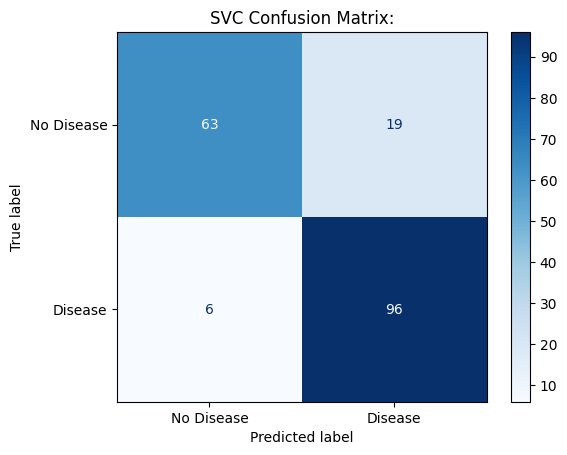


SVC Classification Report:

              precision    recall  f1-score   support

  No Disease       0.91      0.77      0.83        82
     Disease       0.83      0.94      0.88       102

    accuracy                           0.86       184
   macro avg       0.87      0.85      0.86       184
weighted avg       0.87      0.86      0.86       184


SVC ROC Curve:



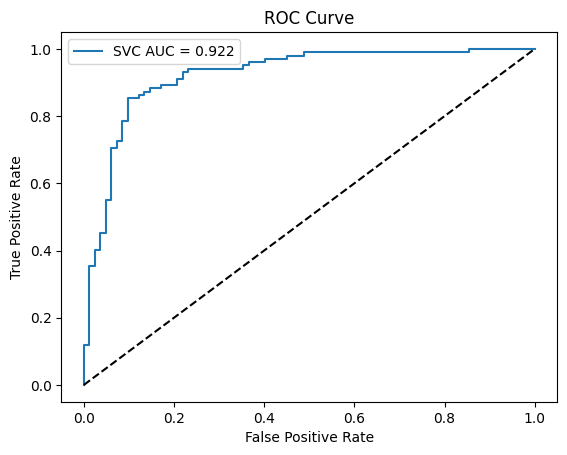

In [20]:
from sklearn.svm import SVC
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve, roc_auc_score)

svc_pipeline = Pipeline([("preprocessor", create_preprocessor()), ("model", SVC(kernel = 'rbf', probability = True, random_state = 42))])

svc_pipeline.fit(X_train, y_train)

svc_predictions = svc_pipeline.predict(X_test)

svc_probabilities = svc_pipeline.predict_proba(X_test)[:, 1]

svc_auc = roc_auc_score(y_test, svc_probabilities)

ConfusionMatrixDisplay.from_predictions(y_test, svc_predictions, display_labels = ['No Disease', 'Disease'], cmap = "Blues")
plt.title("SVC Confusion Matrix:")
plt.show()

print("\nSVC Classification Report:\n")
print(classification_report(y_test, svc_predictions, target_names = ['No Disease', 'Disease']))

print("\nSVC ROC Curve:\n")
fpr_svc, tpr_svc, thresholds = roc_curve(y_test, svc_probabilities)
plt.plot(fpr_svc, tpr_svc, label = f'SVC AUC = {svc_auc:.3f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

**Task Six:**
*   The decision tree classifier will make predictions by dividing our dataset into small groups based on their features. With each step taken a new decision rule is made until the model is complete. To better configure the model and avoid overfitting I set the max_depth to five and the min_samples_leaf to five as well. Without this, the model may become too complex and overfit the data.
*   We will then use the same evaluation metrics from above so that we may directly compare the differences between our SVC model and our decision tree classifier.

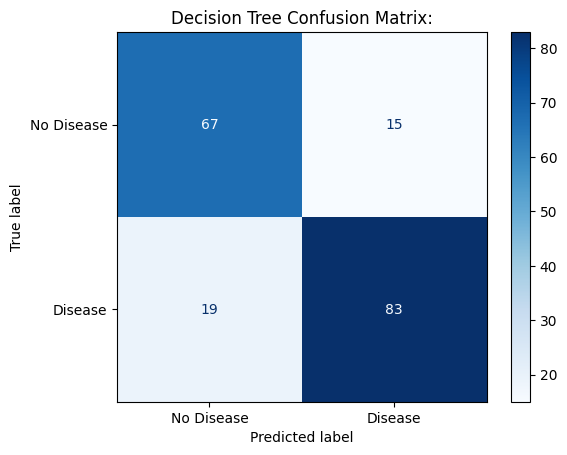


Decision Tree Classification Report:

              precision    recall  f1-score   support

  No Disease       0.78      0.82      0.80        82
     Disease       0.85      0.81      0.83       102

    accuracy                           0.82       184
   macro avg       0.81      0.82      0.81       184
weighted avg       0.82      0.82      0.82       184


Decision Tree ROC Curve:



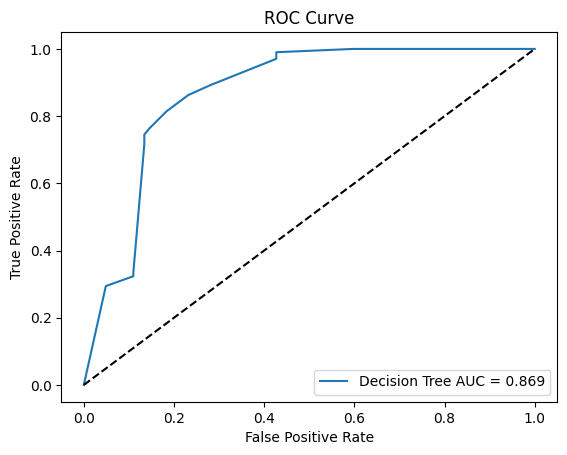

In [23]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve, roc_auc_score)

tree_pipeline = Pipeline([("preprocessor", create_preprocessor()),
    ("model", DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, random_state=42))])

tree_pipeline.fit(X_train, y_train)

tree_predictions = tree_pipeline.predict(X_test)

tree_probabilities = tree_pipeline.predict_proba(X_test)[:, 1]

tree_auc = roc_auc_score(y_test, tree_probabilities)

ConfusionMatrixDisplay.from_predictions(y_test, tree_predictions, display_labels = ['No Disease', 'Disease'], cmap = "Blues")
plt.title("Decision Tree Confusion Matrix:")
plt.show()

print("\nDecision Tree Classification Report:\n")
print(classification_report(y_test, tree_predictions, target_names = ['No Disease', 'Disease']))

print("\nDecision Tree ROC Curve:\n")
fpr_tree, tpr_tree, thresholds = roc_curve(y_test, tree_probabilities)
plt.plot(fpr_tree, tpr_tree, label = f'Decision Tree AUC = {tree_auc:.3f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()


**Task Seven:**
*   Returning our focus to our SVC model, we want to test how different hyperparameters may benefit or harm our model's performance. The two hyperparamter we will be using specifically are C, which controls the regularization strength of the model. In this case, the larger the parameter value, the more it penalizes the errors from the model. Gamma is the hyperparamter that controls how individual training observations influence the decision boundary.  
*   To make the evalution part of this task a lot easier, we will be implementing the GridSearchCV tool to examine each hyperparamter and the combinations of them as well.

